# 07 · Weather-adjusted estimate of the 15 May 2019 raw-coal ban (H6)

**H6.** Weather-adjusted winter PM2.5 at the US Embassy station (OpenAQ 8160) is lower after the 15 May 2019 raw-coal ban than before.

**Method** (weather normalisation used as a counterfactual, in the style of Grange & Carslaw):
1. Train a "no-ban" model of log1p(daily PM2.5) on weather and calendar inputs, using **pre-ban days only** (all months, from 2016-11-09). No date or trend variable: it would absorb the ban.
2. Predict the no-ban level of every post-ban day from that day's weather; convert back to means with Duan's smearing factor.
3. Effect % = observed smog-season mean / counterfactual mean − 1, per winter 2019/20–2023/24 and pooled; a placebo on 2018/19 checks the model.
4. Main model: random forest. Cross-checks: a linear counterfactual and a post-ban dummy regression with HAC standard errors.

**Caveats.** Weather-adjusted, **not causal**: population, fuel briquettes, COVID (2020/21, flagged in every table) and warmer winters also changed. The bootstrap interval resamples 7-day blocks of the pre-ban fit days only, so it reflects model uncertainty only, not the day-to-day noise of the post-ban days (on synthetic data it covers the truth about 75% of the time). On synthetic data the estimator is about 2 points too close to zero (the counterfactual runs slightly low on cold smog days), so effects here are, if anything, conservative.

**Seal.** The 2024/25 test winter is never used: data stop on `ban_effect.end` (2024-06-30). All logic lives in `src/uaq/policy_effect.py`; this notebook only calls it.

In [1]:
# Setup: works whether or not you ran `pip install -e .`
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from uaq.config import load_config, ROOT
from uaq import policy_effect as pe
cfg = load_config()
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
%matplotlib inline
print("Project root:", ROOT)

Project root: /Users/user/Desktop/neural


## 1 · Data and coverage by winter
Daily PM2.5 (valid days only, ≥ 18 of 24 hours; never imputed) and daily ERA5 weather, 2016-11-09 to 2024-06-30. The pre-ban winters are patchy (48–85% of smog-season days valid).

In [2]:
df = pe.build_daily(cfg)
END, BAN = pd.Timestamp(cfg["ban_effect"]["end"]), pd.Timestamp(cfg["structural_break"])
assert df["date"].max() <= END, "the 2024/25 test winter is sealed"
print(f"{len(df):,} days, {df['date'].min().date()} to {df['date'].max().date()}; ban {BAN.date()}")
print(f"Valid PM2.5 days: {int(df['pm25'].notna().sum()):,} "
      f"(pre-ban {int((df['pm25'].notna() & ~df['post']).sum())}, post-ban {int((df['pm25'].notna() & df['post']).sum())})")
print("Model inputs (no date or trend):", pe.input_columns(cfg))
cov = pe.coverage_by_season(df)
display(cov.style.format({"share_valid": "{:.0%}", "observed_mean": "{:.1f}"}))

2,791 days, 2016-11-09 to 2024-06-30; ban 2019-05-15
Valid PM2.5 days: 1,616 (pre-ban 585, post-ban 1031)
Model inputs (no date or trend): ['temp_mean', 'temp_min', 'temp_range', 'rh_mean', 'pressure_mean', 'wind_mean', 'calm_hours', 'wind_u', 'wind_v', 'doy_sin', 'doy_cos', 'dow_sin', 'dow_cos']


,period,smog_days,valid_days,share_valid,observed_mean,covid
season,,,,,,
2016/17,pre-ban,112,67,60%,146.6,False
2017/18,pre-ban,120,57,48%,109.8,False
2018/19,pre-ban,120,102,85%,172.6,False
2019/20,post-ban,121,107,88%,120.8,False
2020/21,post-ban,120,65,54%,101.4,True
2021/22,post-ban,120,111,92%,129.7,False
2022/23,post-ban,120,0,0%,nan,False
2023/24,post-ban,121,108,89%,111.7,False


## 2 · Placebo on 2018/19 (pre-ban)
Fit on the pre-ban winters before 2018/19, predict 2018/19, which had no ban: the "effect" should be near 0. Decision rule, fixed before looking at the main result: if the forest's |placebo effect| > 15%, the model is not reliable enough and H6 is reported as inconclusive.

In [3]:
plac = pd.DataFrame({m: pe.placebo(df, cfg, m) for m in ("rf", "linear")}).T.rename_axis("model")
display(plac.style.format({"observed": "{:.1f}", "counterfactual": "{:.1f}", "effect": "{:+.1%}"}))
plac_rf = float(plac.loc["rf", "effect"])
reliable = abs(plac_rf) <= 0.15
display(Markdown(
    f"**Placebo (forest): {plac_rf:+.1%}.** " +
    ("Within ±15%, so the counterfactual model is usable." if reliable else
     "Outside ±15%: the model is **not reliable enough**, and H6 is reported as **inconclusive**.")))

,observed,counterfactual,n_days,covid,effect
model,,,,,
rf,172.6,131.3,102,False,+31.4%
linear,172.6,157.1,102,False,+9.8%


**Placebo (forest): +31.4%.** Outside ±15%: the model is **not reliable enough**, and H6 is reported as **inconclusive**.

## 3 · Main result: random-forest counterfactual, per post-ban winter
Effect % = observed / counterfactual − 1 on smog-season days with a valid daily mean. Interval: 2.5–97.5 percentiles of 500 block-bootstrap refits (pre-ban 7-day blocks; model uncertainty only).

In [4]:
eff_rf, cf_rf = pe.ban_effect(df, cfg, "rf")
int_rf, reps_rf = pe.block_bootstrap(df, cfg, "rf")
main = eff_rf.join(int_rf)[["observed", "counterfactual", "effect", "lo", "hi", "n_days", "covid"]]
display(main.style.format({"observed": "{:.1f}", "counterfactual": "{:.1f}", "effect": "{:+.1%}", "lo": "{:+.1%}", "hi": "{:+.1%}"}))
p = main.loc["pooled"]
display(Markdown(
    f"**Pooled over 2019/20–2023/24** ({int(p['n_days'])} smog-season days, COVID winter included): observed "
    f"{p['observed']:.1f} µg/m³ vs weather-adjusted no-ban {p['counterfactual']:.1f} µg/m³, effect **{p['effect']:+.1%}** "
    f"(95% interval {p['lo']:+.1%} to {p['hi']:+.1%})."))

,observed,counterfactual,effect,lo,hi,n_days,covid
season,,,,,,,
2019/20,120.8,165.0,-26.8%,-30.9%,-15.7%,107,False
2020/21,101.4,146.1,-30.6%,-35.0%,-22.5%,65,True
2021/22,129.7,153.1,-15.3%,-18.7%,-1.8%,111,False
2023/24,111.7,160.8,-30.5%,-34.4%,-22.4%,108,False
pooled,117.6,157.3,-25.2%,-28.9%,-15.0%,391,True


**Pooled over 2019/20–2023/24** (391 smog-season days, COVID winter included): observed 117.6 µg/m³ vs weather-adjusted no-ban 157.3 µg/m³, effect **-25.2%** (95% interval -28.9% to -15.0%).

## 4 · Cross-checks
A linear counterfactual (OLS on the same inputs plus squared temperatures, same bootstrap) and a dummy regression: OLS of log1p(PM2.5) on a post-ban dummy + weather + calendar over every valid day to 2024-06-30, HAC (Newey–West, 7 lags) standard errors. The dummy regression estimates one average shift over **all months**, not the smog season.

In [5]:
eff_lin, cf_lin = pe.ban_effect(df, cfg, "linear")
int_lin, _ = pe.block_bootstrap(df, cfg, "linear")
lin = eff_lin.join(int_lin)[["observed", "counterfactual", "effect", "lo", "hi", "n_days", "covid"]]
display(Markdown("**Linear counterfactual, per winter**"))
display(lin.style.format({"observed": "{:.1f}", "counterfactual": "{:.1f}", "effect": "{:+.1%}", "lo": "{:+.1%}", "hi": "{:+.1%}"}))

did = pe.did_check(df, cfg)
est = pd.DataFrame([
    {"method": "random-forest counterfactual (main)", "days": "smog season", "effect": main.loc["pooled", "effect"],
     "lo": main.loc["pooled", "lo"], "hi": main.loc["pooled", "hi"], "interval": "block bootstrap (model only)",
     "n_days": int(main.loc["pooled", "n_days"]), "includes COVID winter": True},
    {"method": "linear counterfactual", "days": "smog season", "effect": lin.loc["pooled", "effect"],
     "lo": lin.loc["pooled", "lo"], "hi": lin.loc["pooled", "hi"], "interval": "block bootstrap (model only)",
     "n_days": int(lin.loc["pooled", "n_days"]), "includes COVID winter": True},
    {"method": "post-ban dummy regression", "days": "all months", "effect": did["effect"], "lo": did["lo"], "hi": did["hi"],
     "interval": f"HAC, {did['hac_maxlags']} lags", "n_days": did["n_days"], "includes COVID winter": True},
]).set_index("method")
display(Markdown("**All three estimates (pooled post-ban)**"))
display(est.style.format({"effect": "{:+.1%}", "lo": "{:+.1%}", "hi": "{:+.1%}"}))

**Linear counterfactual, per winter**

,observed,counterfactual,effect,lo,hi,n_days,covid
season,,,,,,,
2019/20,120.8,136.8,-11.7%,-19.7%,-3.7%,107,False
2020/21,101.4,135.9,-25.4%,-33.1%,-18.0%,65,True
2021/22,129.7,135.7,-4.4%,-12.7%,+3.4%,111,False
2023/24,111.7,154.7,-27.8%,-37.4%,-19.5%,108,False
pooled,117.6,141.3,-16.8%,-24.8%,-9.3%,391,True


**All three estimates (pooled post-ban)**

,days,effect,lo,hi,interval,n_days,includes COVID winter
method,,,,,,,
random-forest counterfactual (main),smog season,-25.2%,-28.9%,-15.0%,block bootstrap (model only),391,True
linear counterfactual,smog season,-16.8%,-24.8%,-9.3%,block bootstrap (model only),391,True
post-ban dummy regression,all months,-5.3%,-15.7%,+6.4%,"HAC, 7 lags",1616,True


## 5 · Observed vs weather-adjusted ("no-ban") smog-season mean

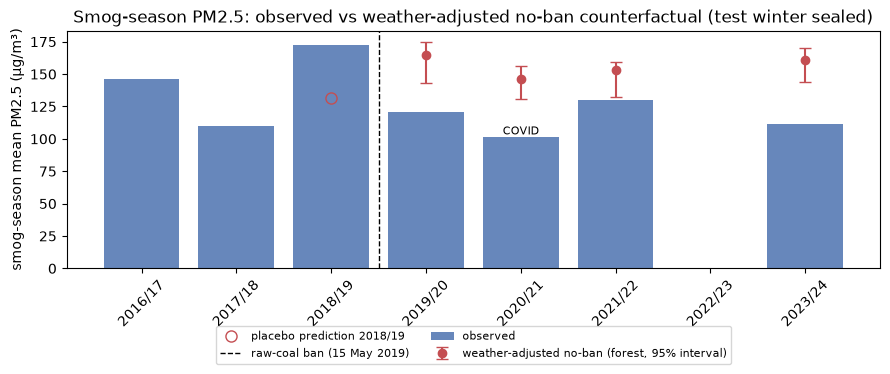

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(cov))
ax.bar(x, cov["observed_mean"], color="#4C72B0", alpha=0.85, label="observed")
post = [s for s in cov.index if s in main.index]
xi = [list(cov.index).index(s) for s in post]
obs, cf = main.loc[post, "observed"], main.loc[post, "counterfactual"]
cf_lo, cf_hi = obs / (1 + main.loc[post, "hi"]), obs / (1 + main.loc[post, "lo"])
ax.errorbar(xi, cf, yerr=[cf - cf_lo, cf_hi - cf], fmt="o", color="#C44E52", capsize=4,
            label="weather-adjusted no-ban (forest, 95% interval)")
hold = [s for s in cov.index if s.startswith(str(cfg["ban_effect"]["placebo_holdout_season"]))][0]
ax.plot(list(cov.index).index(hold), plac.loc["rf", "counterfactual"], "o", mfc="none", mec="#C44E52", ms=8,
        label=f"placebo prediction {hold}")
ban_x = list(cov.index).index(post[0]) - 0.5
ax.axvline(ban_x, color="k", ls="--", lw=1, label="raw-coal ban (15 May 2019)")
for i, s in enumerate(cov.index):
    if cov.loc[s, "covid"]:
        ax.annotate("COVID", (i, cov.loc[s, "observed_mean"]), ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, cov.index, rotation=45); ax.set_ylabel("smog-season mean PM2.5 (µg/m³)")
ax.set_title("Smog-season PM2.5: observed vs weather-adjusted no-ban counterfactual (test winter sealed)")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
fig.tight_layout(); plt.show()

In [7]:
p = main.loc["pooled"]
if not reliable:
    verdict = "inconclusive (placebo outside ±15%)"
elif p["hi"] < 0:
    verdict = "supported (pooled interval below 0)"
elif p["lo"] > 0:
    verdict = "contradicted (pooled interval above 0)"
else:
    verdict = "not supported (pooled interval includes 0)"
agree = all(np.sign(v) == np.sign(p["effect"]) for v in est["effect"])
display(Markdown(
    f"**H6: {verdict}.** Forest pooled effect {p['effect']:+.1%} ({p['lo']:+.1%} to {p['hi']:+.1%}); the cross-checks give "
    f"{est.loc['linear counterfactual', 'effect']:+.1%} (linear) and {did['effect']:+.1%} (dummy regression, all months), "
    + ("all with the same sign." if agree else "and do not all agree in sign.")
    + " Weather-adjusted, not causal."))

**H6: inconclusive (placebo outside ±15%).** Forest pooled effect -25.2% (-28.9% to -15.0%); the cross-checks give -16.8% (linear) and -5.3% (dummy regression, all months), all with the same sign. Weather-adjusted, not causal.

## 6 · Save

In [8]:
out = ROOT / "outputs" / "results"
rows = []
for method, tab in (("rf", main), ("linear", lin)):
    rows.append(tab.reset_index().assign(method=method, kind="post-ban"))
rows.append(plac.reset_index().rename(columns={"model": "method"}).assign(season=hold, kind="placebo", lo=np.nan, hi=np.nan))
rows.append(pd.DataFrame([{"season": "all post-ban days (all months)", "method": "dummy regression", "kind": "post-ban",
                           "effect": did["effect"], "lo": did["lo"], "hi": did["hi"], "n_days": did["n_days"], "covid": True}]))
table = pd.concat(rows, ignore_index=True)[["kind", "method", "season", "observed", "counterfactual", "effect", "lo", "hi",
                                            "n_days", "covid"]]
table.to_csv(out / "ban_effect.csv", index=False)

summary = {
    "run_date": pd.Timestamp.now().strftime("%Y-%m-%d"),
    "hypothesis": "H6: weather-adjusted winter PM2.5 is lower after the 15 May 2019 raw-coal ban than before",
    "verdict": verdict,
    "data": {"start": str(df["date"].min().date()), "end": str(df["date"].max().date()), "ban": str(BAN.date()),
             "valid_days_pre_ban": int((df["pm25"].notna() & ~df["post"]).sum()),
             "valid_days_post_ban": int((df["pm25"].notna() & df["post"]).sum())},
    "inputs": pe.input_columns(cfg),
    "placebo": {m: {"season": hold, "effect": float(plac.loc[m, "effect"]), "n_days": int(plac.loc[m, "n_days"])} for m in plac.index},
    "placebo_rule": "H6 inconclusive if |forest placebo effect| > 15%",
    "pooled": {m: {"effect": float(t.loc["pooled", "effect"]), "lo": float(t.loc["pooled", "lo"]), "hi": float(t.loc["pooled", "hi"]),
                   "n_days": int(t.loc["pooled", "n_days"])} for m, t in (("rf", main), ("linear", lin))},
    "dummy_regression": did,
    "bootstrap": {**cfg["ban_effect"]["bootstrap"], "note": "pre-ban fit blocks resampled, post-ban days fixed: model uncertainty only"},
    "caveats": ["weather-adjusted, not causal (population, fuel briquettes, COVID, warmer winters)",
                "COVID winter 2020/21 included in the pooled estimates",
                "pre-ban winters are 48-85% complete",
                "on synthetic data the estimator is ~2 points too close to zero; the interval covers the truth ~75% of the time"],
}
(out / "ban_effect.json").write_text(json.dumps(summary, indent=2, default=float), encoding="utf-8")
for f in ("ban_effect.csv", "ban_effect.json"):
    print("Saved", out / f)

Saved /Users/user/Desktop/neural/outputs/results/ban_effect.csv
Saved /Users/user/Desktop/neural/outputs/results/ban_effect.json
